# IoT Intrusion Detection Using Machine Learning
## Report 2 — Implementation and Results

This notebook develops and evaluates machine-learning models for identifying suspicious traffic in an Internet of Things (IoT) network dataset.

**Dataset:** `IoT_Intrusion.csv` (the notebook initially expects approximately 1,048,575 rows and 47 columns; the actual loaded shape is printed below).

**Algorithms compared:**
- **Decision Tree Classifier:** a single-tree baseline that is relatively easy to interpret.
- **Random Forest Classifier:** an ensemble of 100 decision trees that combines their predictions.

**Prediction tasks:**
1. **Binary classification:** classify each record as `Normal` or `Attack`.
2. **Eight-class classification:** assign each record to one of eight broader traffic categories.

The workflow covers data inspection, duplicate removal, target construction, exploratory analysis, train/test splitting, model training, evaluation, interpretability, feature importance, and saving the trained Random Forest models.

## 1. Import Libraries

The first code cell imports the Python libraries required for data handling, visualization, model training, and evaluation. These imports are shared by the later notebook steps.

### Libraries and Tools

This cell imports the libraries used throughout the experiment.

- **pandas (`pd`)** loads and manipulates the tabular network-traffic dataset.
- **NumPy (`np`)** supports numerical operations, including checking infinite values and creating target labels.
- **Matplotlib** and **Seaborn** create plots for class distribution, feature correlation, confusion matrices, and feature importance.
- **`train_test_split`** separates data into training and testing subsets.
- **`DecisionTreeClassifier`** trains a single decision tree that acts as a baseline model.
- **`RandomForestClassifier`** trains an ensemble of decision trees and is the primary model being evaluated.
- **Metrics and reporting functions** measure predictive performance and help identify classes that are missed.

The plotting style and pandas display options are configured for clearer notebook output.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

c:\Users\BALAMURUGAN\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 2. Load and Inspect the Dataset

Load the CSV file into a DataFrame and inspect its first rows and schema. These checks confirm that the expected file is available and show the fields that will be used during preparation.

### Load the Dataset

The CSV file `IoT_Intrusion.csv` is read into a pandas DataFrame named `df`. The shape output shows the number of rows and columns, while `head()` displays the first few records so the column names and data format can be checked.

The dataset contains network-traffic observations and a `label` column that identifies the traffic type. Make sure the CSV file is in the notebook's working directory, or update the path to its actual location.

In [2]:
df = pd.read_csv("IoT_Intrusion.csv")
print("Shape:", df.shape)
df.head()

Shape: (1048575, 47)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,urg_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,54.00,6.00,64.00,0.329807,0.329807,0.0,1,0,1,0,0,0,0,1.0,0.00,1.00,0.0,0.00,0,0,0,0,0,0,0,1,0,0,0,0,1,1,567.00,54.00,54.0,54.000000,0.000000,54.00,83343831.92,9.5,10.392305,0.000000,0.000000,0.00,141.55,DDoS-RSTFINFlood
1,0.000000,57.04,6.33,64.00,4.290556,4.290556,0.0,0,0,0,0,0,0,0,0.0,0.00,0.00,0.0,0.00,1,0,0,0,0,0,0,1,0,0,0,0,1,1,581.33,54.00,66.3,54.796404,2.822973,57.04,82926067.47,9.5,10.464666,4.010353,160.987842,0.05,141.55,DoS-TCP_Flood
2,0.000000,0.00,1.00,64.00,33.396799,33.396799,0.0,0,0,0,0,0,0,0,0.0,0.00,0.00,0.0,0.00,0,0,0,0,0,0,0,0,0,0,0,1,1,1,441.00,42.00,42.0,42.000000,0.000000,42.00,83127993.93,9.5,9.165151,0.000000,0.000000,0.00,141.55,DDoS-ICMP_Flood
3,0.328175,76175.00,17.00,64.00,4642.133010,4642.133010,0.0,0,0,0,0,0,0,0,0.0,0.00,0.00,0.0,0.00,0,0,0,0,0,0,0,0,1,0,0,0,1,1,525.00,50.00,50.0,50.000000,0.000000,50.00,83015696.38,9.5,10.000000,0.000000,0.000000,0.00,141.55,DoS-UDP_Flood
4,0.117320,101.73,6.11,65.91,6.202211,6.202211,0.0,0,1,0,0,0,0,0,0.0,1.01,0.04,0.0,0.02,0,0,0,0,0,0,0,1,0,0,0,0,1,1,644.60,57.88,131.6,67.959230,23.113111,57.88,82972999.18,9.5,11.346876,32.716243,3016.808286,0.19,141.55,DoS-SYN_Flood


### Inspect Column Types and Non-Null Counts

`df.info()` reports the number of records, column names, data types, and non-null values. This helps confirm which columns are numeric and whether any columns have missing values.

The model expects usable feature values, so this inspection is an early check before data cleaning and model training.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 47 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   flow_duration    1048575 non-null  float64
 1   Header_Length    1048575 non-null  float64
 2   Protocol Type    1048575 non-null  float64
 3   Duration         1048575 non-null  float64
 4   Rate             1048575 non-null  float64
 5   Srate            1048575 non-null  float64
 6   Drate            1048575 non-null  float64
 7   fin_flag_number  1048575 non-null  int64  
 8   syn_flag_number  1048575 non-null  int64  
 9   rst_flag_number  1048575 non-null  int64  
 10  psh_flag_number  1048575 non-null  int64  
 11  ack_flag_number  1048575 non-null  int64  
 12  ece_flag_number  1048575 non-null  int64  
 13  cwr_flag_number  1048575 non-null  int64  
 14  ack_count        1048575 non-null  float64
 15  syn_count        1048575 non-null  float64
 16  fin_count        1048575 non-

## 3. Data Quality Checks

Before training, check for missing values, infinite numeric values, duplicate rows, and constant columns. These checks help reveal data problems that could affect training or evaluation.

### Check Data Quality

This cell checks four common data-quality issues:

1. **Missing values:** counts all null cells in the dataset.
2. **Infinite numeric values:** checks numeric columns for positive or negative infinity.
3. **Duplicate records:** counts rows that are exact duplicates of earlier rows.
4. **Constant columns:** identifies columns with only one unique value, which cannot help distinguish traffic classes.

These checks describe potential issues; the following cleaning and feature-preparation steps address duplicates and constant columns. The notebook does not impute missing values, so the reported null count should be reviewed before training.

In [4]:
print("Null values:", df.isnull().sum().sum())
print("Infinite values:", np.isinf(df.select_dtypes(include=[np.number])).sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Constant columns:", [c for c in df.columns if df[c].nunique() <= 1])

Null values: 0
Infinite values: 0
Duplicate rows: 65556
Constant columns: ['ece_flag_number', 'cwr_flag_number', 'Telnet', 'SMTP', 'IRC']


## 4. Remove Duplicate Rows

Remove exact duplicate records before splitting the data. This reduces repeated observations and helps avoid identical rows appearing in both the training and test sets.

### Remove Duplicate Records

Exact duplicate rows are removed using `drop_duplicates()`, and the index is reset afterward. The notebook prints how many rows were removed and how many remain.

Removing duplicates before the train/test split helps prevent identical records from appearing in both subsets and making evaluation look more optimistic. This operation removes exact duplicates only; it does not determine whether similar but non-identical traffic records are related.

In [5]:
raw_rows = len(df)
df = df.drop_duplicates().reset_index(drop=True)
clean_rows = len(df)
print(f"Removed {raw_rows - clean_rows} duplicate rows -> {clean_rows} rows remain")

Removed 65556 duplicate rows -> 983019 rows remain


## 5. Build Target Labels and Prepare Features

The original `label` column contains detailed traffic labels. This step maps those labels to two prediction targets: binary `Normal`/`Attack` labels and eight broader traffic categories. It also removes target columns and constant columns from the input feature matrix to avoid target leakage and uninformative features.

### Inspect the Original Labels

The raw `label` column contains the original traffic labels. `nunique()` reports how many distinct labels exist, and `value_counts()` shows the number of records for each label.

This is important because some attack types are much more common than others. Such imbalance can make overall accuracy look high even when the model misses less frequent attacks.

In [6]:
print("Number of unique raw labels:", df["label"].nunique())
df["label"].value_counts()

Number of unique raw labels: 34


label
DDoS-ICMP_Flood            137288
DDoS-UDP_Flood             121205
DDoS-TCP_Flood              92028
DDoS-SYN_Flood              86191
DDoS-PSHACK_Flood           83914
DDoS-SynonymousIP_Flood     78994
DDoS-RSTFINFlood            78439
DoS-UDP_Flood               74138
DoS-TCP_Flood               57493
DoS-SYN_Flood               44389
BenignTraffic               24476
Mirai-greeth_flood          21817
Mirai-udpplain              20166
Mirai-greip_flood           16746
DDoS-ICMP_Fragmentation     10216
MITM-ArpSpoofing             7019
DDoS-UDP_Fragmentation       6431
DDoS-ACK_Fragmentation       6429
DNS_Spoofing                 4034
Recon-HostDiscovery          3007
Recon-OSScan                 2225
Recon-PortScan               1863
DoS-HTTP_Flood               1680
VulnerabilityScan             809
DDoS-HTTP_Flood               626
DDoS-SlowLoris                493
DictionaryBruteForce          324
BrowserHijacking              140
SqlInjection                  122
CommandI

### Create Binary and Eight-Class Targets; Prepare Features

The `group()` function maps the original labels into eight broader categories:

- **Benign:** `BenignTraffic`
- **DDoS:** labels beginning with `DDoS`
- **DoS:** labels beginning with `DoS`
- **Mirai:** labels beginning with `Mirai`
- **Recon:** labels beginning with `Recon`, plus `VulnerabilityScan`
- **Spoofing:** `MITM-ArpSpoofing` and `DNS_Spoofing`
- **BruteForce:** `DictionaryBruteForce`
- **Web-based:** any remaining labels

Two prediction targets are created:
- **`binary`:** `Normal` for benign traffic and `Attack` for every other raw label.
- **`category`:** the eight broader traffic categories above.

The feature matrix `X` excludes the original label and both derived targets, preventing the answers from being used as input features. Constant columns are also removed because they provide no variation for learning. The resulting `X` is used as the input data for both tasks.

The grouping rules are a project-specific mapping; confirm that the original dataset's label names match these rules before interpreting results.

In [7]:
def group(l):
    if l == "BenignTraffic":
        return "Benign"
    if l.startswith("DDoS"):
        return "DDoS"
    if l.startswith("DoS"):
        return "DoS"
    if l.startswith("Mirai"):
        return "Mirai"
    if l.startswith("Recon") or l == "VulnerabilityScan":
        return "Recon"
    if l in ("MITM-ArpSpoofing", "DNS_Spoofing"):
        return "Spoofing"
    if l == "DictionaryBruteForce":
        return "BruteForce"
    return "Web-based"

df["category"] = df["label"].map(group)
df["binary"] = np.where(df["label"] == "BenignTraffic", "Normal", "Attack")

# Complete Data Cleaning: Drop 5 constant zero-variance columns along with target columns
constant_cols = [c for c in df.columns if df[c].nunique() <= 1]
print("Dropping constant zero-variance columns:", constant_cols)
X = df.drop(columns=["label", "category", "binary"] + constant_cols)
print("Number of cleaned features:", X.shape[1])
X.columns.tolist()

Number of features: 46


['flow_duration',
 'Header_Length',
 'Protocol Type',
 'Duration',
 'Rate',
 'Srate',
 'Drate',
 'fin_flag_number',
 'syn_flag_number',
 'rst_flag_number',
 'psh_flag_number',
 'ack_flag_number',
 'ece_flag_number',
 'cwr_flag_number',
 'ack_count',
 'syn_count',
 'fin_count',
 'urg_count',
 'rst_count',
 'HTTP',
 'HTTPS',
 'DNS',
 'Telnet',
 'SMTP',
 'SSH',
 'IRC',
 'TCP',
 'UDP',
 'DHCP',
 'ARP',
 'ICMP',
 'IPv',
 'LLC',
 'Tot sum',
 'Min',
 'Max',
 'AVG',
 'Std',
 'Tot size',
 'IAT',
 'Number',
 'Magnitue',
 'Radius',
 'Covariance',
 'Variance',
 'Weight']

## 6. Exploratory Data Analysis (EDA)

Exploratory analysis helps describe the dataset before model fitting. The following sections inspect the class distribution and correlations between numeric features. These checks are important because the dataset contains imbalanced classes and some features may provide overlapping information.

### 6.1 Class Distribution

Review the number of records in the binary target and in each of the eight categories. Then visualize the category counts to identify frequent and rare classes.

### Count the Classes

These counts show how many records belong to each binary class and each of the eight broader categories. The counts are used to understand the dataset's class balance before training.

If one category contains far fewer examples than another, a model may favor the common category. For that reason, the project evaluates macro-averaged metrics and per-class reports in addition to accuracy.

In [8]:
print(df["binary"].value_counts(), "\n")
print(df["category"].value_counts())

binary
Attack    958543
Normal     24476
Name: count, dtype: int64 

category
DDoS          702254
DoS           177700
Mirai          58729
Benign         24476
Spoofing       11053
Recon           7945
Web-based        538
BruteForce       324
Name: count, dtype: int64


### Visualize the Eight-Class Distribution

This horizontal bar chart displays the number of records in each category after duplicate removal. The bars are ordered by frequency, and labels show the record counts.

Use the chart to identify dominant categories and rare categories. A large imbalance is relevant when evaluating the model: high overall accuracy does not necessarily mean that every attack family is detected reliably.

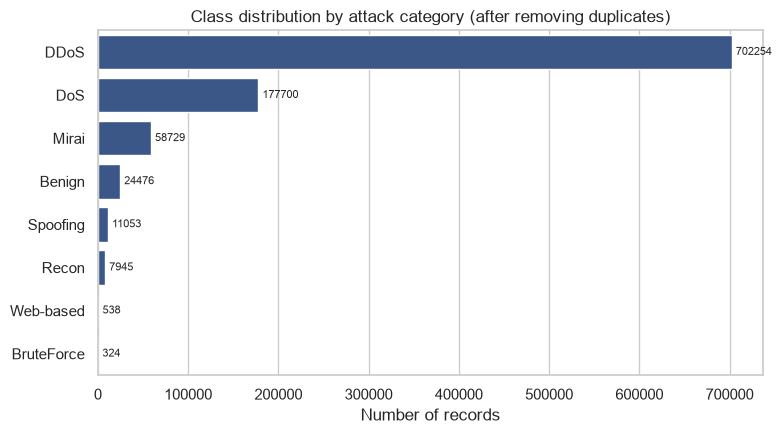

In [9]:
order = df["category"].value_counts().index
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(y="category", data=df, order=order, color="#2E5395", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%d", padding=3, fontsize=8)
ax.set_xlabel("Number of records")
ax.set_ylabel("")
ax.set_title("Class distribution by attack category (after removing duplicates)")
plt.tight_layout()
plt.show()

### 6.2 Feature Correlation

Calculate and visualize pairwise correlations among the numeric input features, then list the strongest correlated feature pairs. Strong correlations can indicate that multiple features carry similar information.

### Plot Feature Correlations

The correlation matrix is calculated for the numeric input features in `X`. The heatmap summarizes pairwise linear correlations: values near **+1** indicate strong positive correlation, values near **−1** indicate strong negative correlation, and values near **0** indicate little linear correlation.

Correlated features can contain overlapping information. Correlation does not establish causation, and low correlation does not necessarily mean that a feature is unimportant to a nonlinear model.

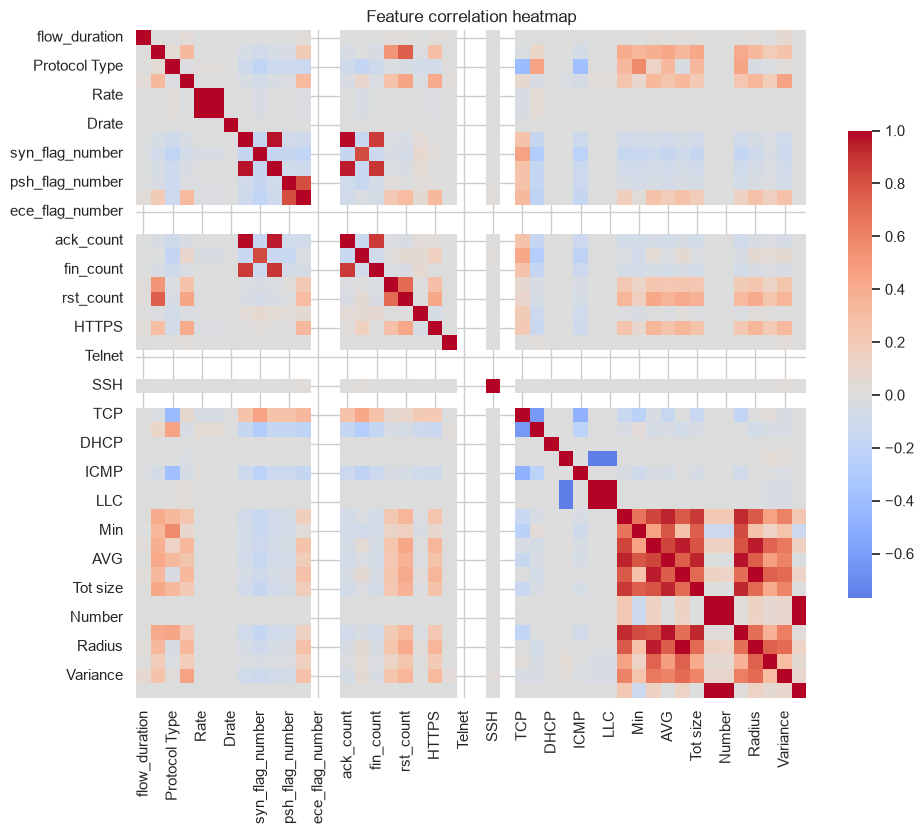

In [10]:
corr = X.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Feature correlation heatmap")
plt.tight_layout()
plt.show()

### Find the Most Strongly Correlated Feature Pairs

This code keeps only one triangle of the absolute correlation matrix, removes self-correlations, and lists the ten strongest remaining pairs.

The output helps identify features that carry similar information. In the discussion, the high correlation between `IAT`, `Weight`, and `Number` is a reason to interpret their individual feature-importance values carefully rather than treating them as independent effects.

In [11]:
# Most strongly correlated feature pairs (excluding self-correlation)
pairs = (corr.abs()
         .where(np.triu(np.ones(corr.shape), 1).astype(bool))
         .stack()
         .sort_values(ascending=False))
pairs.head(10)

Rate             Srate              1.000000
IPv              LLC                1.000000
Std              Radius             0.999961
Number           Weight             0.999588
IAT              Weight             0.997310
                 Number             0.996032
fin_flag_number  ack_count          0.983940
                 rst_flag_number    0.971476
AVG              Magnitue           0.967567
rst_flag_number  ack_count          0.956087
dtype: float64

## 7. Train/Test Split

Divide the data into training and test sets using an 80:20 split. Stratification aims to preserve class proportions, and a fixed random seed makes the split repeatable. The test set is reserved for evaluation after model training.

### Split the Data into Training and Testing Sets

The `make_split()` function separates the feature matrix and a selected target into training and testing subsets.

- **80% training data** is used to fit the models.
- **20% testing data** is held back for evaluation.
- **`stratify=y`** aims to preserve each target class's proportion in both subsets.
- **`random_state=42`** makes the split reproducible.

Separate target splits are created for the binary and eight-class tasks. Since the target columns are not part of `X`, the models receive features rather than the answer labels. Very rare classes may still have limited representation, so their test metrics should be interpreted cautiously.

In [12]:
def make_split(target_col):
    y = df[target_col]
    Xtr, Xte, ytr, yte = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42
    )
    return Xtr, Xte, ytr, yte

Xtr_bin, Xte_bin, ytr_bin, yte_bin = make_split("binary")
Xtr_cat, Xte_cat, ytr_cat, yte_cat = make_split("category")

print("Binary task   -> train:", Xtr_bin.shape, " test:", Xte_bin.shape)
print("Category task -> train:", Xtr_cat.shape, " test:", Xte_cat.shape)

Binary task   -> train: (786415, 46)  test: (196604, 46)
Category task -> train: (786415, 46)  test: (196604, 46)


## 8. Model Training

Train and compare two algorithms—a single Decision Tree and a Random Forest—on both prediction tasks. A Decision Tree provides an interpretable baseline; Random Forest combines many trees and is the main ensemble model in this notebook.

### 8.1 Binary Classification: Normal vs Attack

Train both algorithms using the binary target. The purpose is to distinguish benign network traffic from traffic labeled as an attack.

### Train Models for Binary Intrusion Detection

This section trains two models to distinguish **Normal** traffic from **Attack** traffic.

1. **Decision Tree:** a single tree is trained as a baseline.
2. **Random Forest:** `n_estimators=100` creates an ensemble of 100 decision trees. The trees are trained with randomness in the samples/features used, and their predictions are combined for the final classification.

`random_state=42` supports reproducibility. `n_jobs=-1` allows Random Forest to use the available CPU cores. Both models learn from `Xtr_bin` and `ytr_bin`; the test set is not used during fitting.

In [13]:
dt_bin = DecisionTreeClassifier(random_state=42)
dt_bin.fit(Xtr_bin, ytr_bin)

rf_bin = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_bin.fit(Xtr_bin, ytr_bin)

print("Decision Tree and Random Forest trained on the binary task.")

Decision Tree and Random Forest trained on the binary task.


### 8.2 Multiclass Classification: Eight Traffic Categories

Train both algorithms using the eight-class target. This is a more detailed task because the model must distinguish between broad attack families as well as benign traffic.

### Train Models for Eight-Class Traffic Categorization

This section repeats the model-training process with `category` as the target. The models must predict one of eight categories: Benign, DDoS, DoS, Mirai, Recon, Spoofing, Web-based, or BruteForce.

The Decision Tree provides a single-tree baseline, while the Random Forest combines the predictions of 100 trees. Comparing these models shows how well they distinguish broad attack families, including categories with relatively few examples.

In [14]:
dt_cat = DecisionTreeClassifier(random_state=42)
dt_cat.fit(Xtr_cat, ytr_cat)

rf_cat = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_cat.fit(Xtr_cat, ytr_cat)

print("Decision Tree and Random Forest trained on the 8-class task.")

Decision Tree and Random Forest trained on the 8-class task.


## 9. Model Evaluation

Evaluate each fitted model on the held-out test data. Accuracy is reported alongside macro-averaged and weighted metrics, because the class distribution is imbalanced and accuracy alone may conceal poor detection of rare attack types.

### Evaluate All Four Model/Task Combinations

The `evaluate()` function predicts labels for a held-out test set and calculates several metrics:

- **Accuracy:** proportion of all test records classified correctly.
- **Macro precision, recall, and F1:** calculates the metric separately for each class and then gives every class equal weight. This makes performance on rare classes more visible.
- **Weighted F1:** averages class F1 scores using each class's number of true records as its weight.

`zero_division=0` avoids division warnings when a class has no predicted examples, assigning zero for the affected metric. The function returns the predictions and metrics for each model/task combination. The test results estimate performance on this split; they do not guarantee the same performance on new networks or future traffic.

In [15]:
def evaluate(model, Xte, yte, name):
    pred = model.predict(Xte)
    acc = accuracy_score(yte, pred)
    p, r, f, _ = precision_recall_fscore_support(yte, pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(yte, pred, average="weighted", zero_division=0)
    print(f"--- {name} ---")
    print(f"Accuracy       : {acc:.4f}")
    print(f"Macro Precision: {p:.4f}   Macro Recall: {r:.4f}   Macro F1: {f:.4f}")
    print(f"Weighted F1    : {fw:.4f}")
    return pred, dict(acc=acc, macro_p=p, macro_r=r, macro_f=f, weighted_f=fw)

pred_dt_bin, m1 = evaluate(dt_bin, Xte_bin, yte_bin, "Decision Tree - Binary")
pred_rf_bin, m2 = evaluate(rf_bin, Xte_bin, yte_bin, "Random Forest - Binary")
pred_dt_cat, m3 = evaluate(dt_cat, Xte_cat, yte_cat, "Decision Tree - 8-class")
pred_rf_cat, m4 = evaluate(rf_cat, Xte_cat, yte_cat, "Random Forest - 8-class")

--- Decision Tree - Binary ---
Accuracy       : 0.9957
Macro Precision: 0.9580   Macro Recall: 0.9540   Macro F1: 0.9560
Weighted F1    : 0.9957


--- Random Forest - Binary ---
Accuracy       : 0.9970
Macro Precision: 0.9661   Macro Recall: 0.9718   Macro F1: 0.9689
Weighted F1    : 0.9970


--- Decision Tree - 8-class ---
Accuracy       : 0.9942
Macro Precision: 0.8334   Macro Recall: 0.8363   Macro F1: 0.8348
Weighted F1    : 0.9942


--- Random Forest - 8-class ---
Accuracy       : 0.9950
Macro Precision: 0.9447   Macro Recall: 0.7412   Macro F1: 0.7695
Weighted F1    : 0.9947


### 9.1 Model Comparison Table

Combine the metric results into one table so the Decision Tree and Random Forest can be compared on both tasks.

### Compare Model Performance

The table consolidates the evaluation metrics for the Decision Tree and Random Forest on both tasks. Compare more than accuracy alone:

- For the **binary task**, consider whether Random Forest improves detection of attacks while limiting false alarms.
- For the **eight-class task**, pay close attention to macro recall and macro F1, because the categories are imbalanced.
- A model can have high accuracy yet perform poorly on rare attack families.

Use the actual values produced by the preceding evaluation cell when reporting results. Do not infer that a model is better on every metric simply because its accuracy is higher.

In [16]:
results = pd.DataFrame([
    dict(Task="Binary", Model="Decision Tree", **m1),
    dict(Task="Binary", Model="Random Forest", **m2),
    dict(Task="8-class", Model="Decision Tree", **m3),
    dict(Task="8-class", Model="Random Forest", **m4),
])
results

,Task,Model,acc,macro_p,macro_r,macro_f,weighted_f
0,Binary,Decision Tree,0.995748,0.958036,0.954023,0.956021,0.995738
1,Binary,Random Forest,0.996963,0.966109,0.971767,0.968920,0.996973
2,8-class,Decision Tree,0.994212,0.833353,0.836340,0.834821,0.994214
3,8-class,Random Forest,0.995010,0.944702,0.741224,0.769523,0.994670


### 9.2 Classification Report: Random Forest Binary Task

Inspect class-wise precision, recall, F1-score, and support for the Random Forest's Normal-versus-Attack predictions.

### Classification Report: Random Forest Binary Task

The classification report gives precision, recall, F1-score, and support for each binary class.

- **Precision:** of the records predicted as a class, how many truly belong to it.
- **Recall:** of the records that truly belong to a class, how many the model detected.
- **F1-score:** harmonic mean of precision and recall.
- **Support:** number of true test examples for that class.

For intrusion detection, Attack recall is especially important because low recall means some attacks are incorrectly classified as Normal. Normal-class precision and recall also matter because false alarms can burden a monitoring system.

In [17]:
print(classification_report(yte_bin, pred_rf_bin, zero_division=0))

              precision    recall  f1-score   support

      Attack       1.00      1.00      1.00    191709
      Normal       0.93      0.95      0.94      4895

    accuracy                           1.00    196604
   macro avg       0.97      0.97      0.97    196604
weighted avg       1.00      1.00      1.00    196604



### 9.3 Classification Report: Random Forest Eight-Class Task

Inspect class-wise metrics for the eight-class Random Forest. Focus on the rare classes as well as the high-volume categories.

### Classification Report: Random Forest Eight-Class Task

This report evaluates each of the eight traffic categories individually. Use **support** to understand how many test examples back each score, and inspect precision, recall, and F1 for rare categories such as Web-based and BruteForce.

A rare class can have poor recall even when the overall accuracy is very high. This report therefore helps reveal weaknesses that a single accuracy value would hide.

In [18]:
print(classification_report(yte_cat, pred_rf_cat, zero_division=0))

              precision    recall  f1-score   support

      Benign       0.90      0.97      0.94      4895
  BruteForce       0.89      0.26      0.40        65
        DDoS       1.00      1.00      1.00    140451
         DoS       1.00      1.00      1.00     35540
       Mirai       1.00      1.00      1.00     11746
       Recon       0.87      0.78      0.82      1589
    Spoofing       0.89      0.85      0.87      2211
   Web-based       1.00      0.07      0.12       107

    accuracy                           1.00    196604
   macro avg       0.94      0.74      0.77    196604
weighted avg       1.00      1.00      0.99    196604



## 10. Confusion Matrices

Confusion matrices show where predictions are correct and which classes are confused with one another. These matrices are row-normalized so each row shows the proportions of an actual class assigned to the predicted classes.

### Confusion Matrix: Binary Classification

The helper function calculates a confusion matrix and normalizes each row by the number of actual examples in that class. The heatmap therefore displays the proportion of each actual class assigned to each predicted class.

- The **vertical axis** represents the actual class.
- The **horizontal axis** represents the predicted class.
- Values near **1.00 on the diagonal** indicate correct classification.
- Off-diagonal values indicate mistakes.

This plot is generated for the Random Forest binary task. Because each row is normalized, read the values as proportions rather than raw record counts.

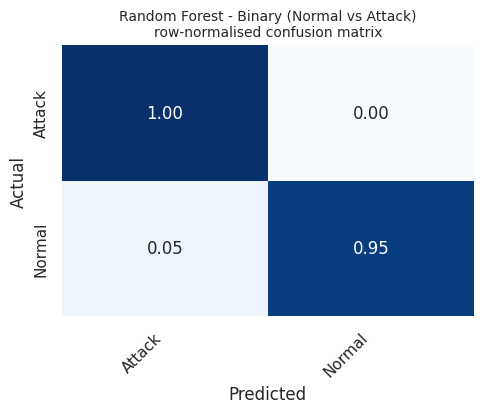

In [19]:
def plot_cm(yte, pred, labels, title, figsize=(5, 4.3)):
    cm = confusion_matrix(yte, pred, labels=labels)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title, fontsize=10)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    return cm

labels_bin = sorted(df["binary"].unique())
cm_bin = plot_cm(yte_bin, pred_rf_bin, labels_bin,
                  "Random Forest - Binary (Normal vs Attack)\nrow-normalised confusion matrix")

### Confusion Matrix: Eight-Class Classification

This row-normalized confusion matrix shows how the Random Forest classifies each of the eight actual categories. Diagonal values represent the proportion correctly assigned to each category; off-diagonal values show which categories are confused with others.

Use this plot to identify attack families with weak recall and common confusion patterns. The visualization is especially useful for class-imbalanced datasets because it shows class-wise performance rather than allowing the largest class to dominate the display.

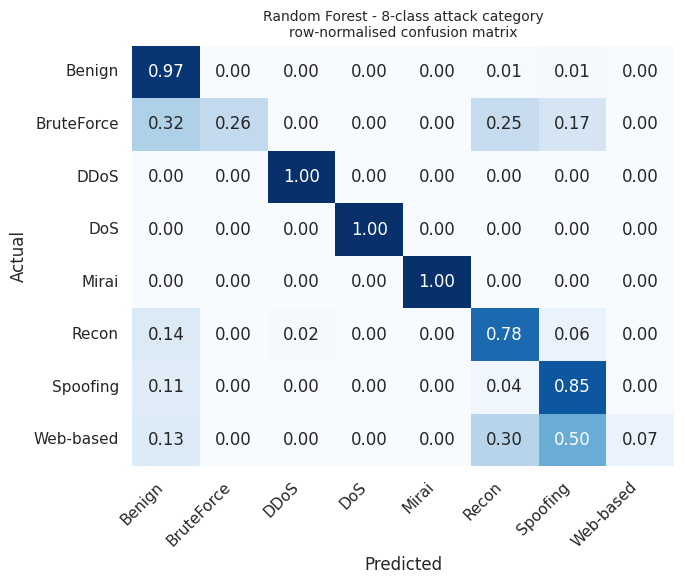

In [20]:
labels_cat = sorted(df["category"].unique())
cm_cat = plot_cm(yte_cat, pred_rf_cat, labels_cat,
                  "Random Forest - 8-class attack category\nrow-normalised confusion matrix",
                  figsize=(7, 6))

## 11. Decision Tree Structure and Interpretability

Visualize the fitted Decision Trees to inspect example decision rules. The plots are limited to depth three for readability. These visualizations explain the single Decision Tree models; they do not show the full internal structure of the Random Forest.

### Visualize the Binary Decision Tree

This plot shows the upper levels of the trained binary Decision Tree, limited to a depth of three for readability. Each split tests a feature threshold; branches represent outcomes of that test, and leaf nodes provide class predictions.

The plot can help explain how the baseline tree separates Normal traffic from Attack traffic. It is a truncated visualization of the trained tree, not a complete display of every possible branch. The tree visualization does not explain the Random Forest as a whole, because the forest contains many trees.

In [ ]:
# 11.1 Binary Decision Tree Visualization (max_depth=3 for readability)
plt.figure(figsize=(20, 10), dpi=300)
plot_tree(
    dt_bin,
    max_depth=3,
    feature_names=list(X.columns),
    class_names=sorted(list(df["binary"].unique())),
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Structure — Binary (Normal vs Attack, Depth=3)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Visualize the Eight-Class Decision Tree and Print Rules

The first part plots the upper levels of the trained eight-class Decision Tree, again limiting the display to depth three so the rules remain readable. The second part prints text-form decision rules up to the same depth.

These rules provide an interpretable view of how a single tree divides traffic using feature thresholds. They can support discussion of model behavior, but they should not be presented as the full logic of the Random Forest, which aggregates predictions from many trees.

In [ ]:
# 11.2 Multi-Class (8-Category) Decision Tree Visualization & Text Rules
plt.figure(figsize=(24, 12), dpi=300)
plot_tree(
    dt_cat,
    max_depth=3,
    feature_names=list(X.columns),
    class_names=sorted(list(df["category"].unique())),
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("Decision Tree Structure — 8-Class IoT Threat Categorization (Depth=3)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Print text rules
print("=== DECISION RULES (8-CLASS) ===")
print(export_text(dt_cat, feature_names=list(X.columns), max_depth=3))

## 12. Random Forest Feature Importance

Rank input features by the Random Forest's impurity-based importance scores for the eight-class task. Use the chart as an indication of which features the fitted model relied on most, while remembering that correlated features can share importance.

### Inspect Random Forest Feature Importance

The `feature_importances_` attribute provides the Random Forest's impurity-based importance scores for the eight-class task. The code sorts the features and plots the 15 highest-scoring ones.

A higher score indicates that a feature contributed more to reducing split impurity across the fitted forest. These scores are model-specific and do not prove that a feature causes an attack. When features are strongly correlated, importance can be shared or redistributed between them, so interpret the ranking alongside the correlation analysis.

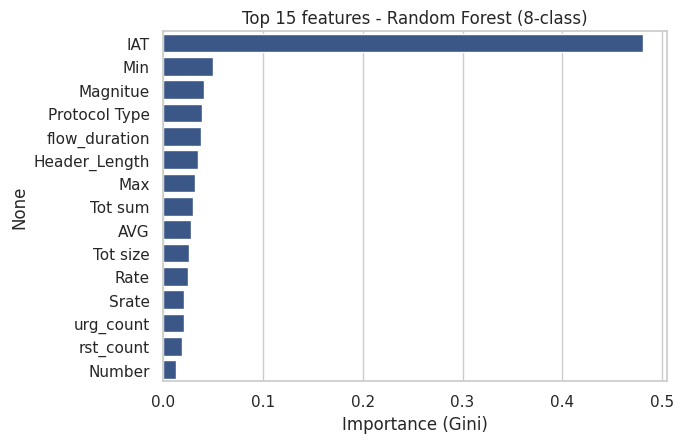

IAT              0.480508
Min              0.049841
Magnitue         0.040849
Protocol Type    0.039170
flow_duration    0.038328
Header_Length    0.034617
Max              0.032420
Tot sum          0.030166
AVG              0.027839
Tot size         0.025806
Rate             0.024588
Srate            0.021351
urg_count        0.020703
rst_count        0.018441
Number           0.012767
dtype: float64

In [21]:
importances = pd.Series(rf_cat.feature_importances_, index=X.columns).sort_values(ascending=False)
top15 = importances.head(15)

fig, ax = plt.subplots(figsize=(7, 4.6))
sns.barplot(x=top15.values, y=top15.index, color="#2E5395", ax=ax)
ax.set_xlabel("Importance (Gini)")
ax.set_title("Top 15 features - Random Forest (8-class)")
plt.tight_layout()
plt.show()

top15

## 13. Discussion

The reported results show strong overall accuracy, but class imbalance affects how well rare attacks are detected. The largest traffic categories dominate accuracy, while the rare Web-based and BruteForce categories are more difficult to identify. For the eight-class task, macro-averaged metrics are particularly important because they give every class equal weight.

The notebook also indicates that `IAT` has the largest feature-importance score and is strongly correlated with `Weight` and `Number`. These correlated importance scores should be interpreted together. Consult the generated evaluation outputs when quoting exact values, since results depend on the dataset and the current notebook run.

## 15. Save the Trained Models for Deployment

Save the fitted Random Forest models with `joblib` so they can be loaded for later prediction. The binary model detects Normal versus Attack traffic; the category model predicts one of the eight broader categories. Deployment must use the same input features, feature order, and preparation process as training.

### 14. Serialization of the Trained Machine Learning Models

Serialization converts a trained machine learning model into a file so it can be stored and reused later. This notebook saves both Random Forest models using Joblib:

- `models/rf_binary_model.joblib` predicts **Normal** versus **Attack**.
- `models/rf_category_model.joblib` predicts one of the **eight traffic categories**.
- `models/feature_columns.json` records the feature names and their expected order.

Saving a model avoids retraining it whenever predictions are needed. The feature list is also saved because new input data must use the same feature columns in the same order as the training data.

In [ ]:
from pathlib import Path
import json
import joblib

# Create a folder for the reusable model artifacts.
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

# Serialize the trained Random Forest models.
joblib.dump(rf_bin, model_dir / "rf_binary_model.joblib")
joblib.dump(rf_cat, model_dir / "rf_category_model.joblib")

# Save the expected feature names and their order.
with open(model_dir / "feature_columns.json", "w", encoding="utf-8") as f:
    json.dump(X.columns.tolist(), f, indent=2)

print("Models and feature metadata saved successfully:")
print(model_dir / "rf_binary_model.joblib")
print(model_dir / "rf_category_model.joblib")
print(model_dir / "feature_columns.json")

## 15. Reusability of the Saved Machine Learning Models

The saved models can be loaded from their Joblib files and used to make predictions without repeating the training process. This demonstrates **model reusability**.

The following cell loads the serialized binary and multiclass Random Forest models. It then uses them to predict a small batch of held-out test records. The test feature sets were created earlier in the notebook, and the models are not fitted again in this section.

The input must contain the same numeric feature columns in the same order as the training data. In a deployed application, apply the same preprocessing used during training before calling `predict()`.

In [ ]:
import joblib
import json
from pathlib import Path

model_dir = Path("models")

# Load the previously saved models. No training occurs here.
loaded_rf_bin = joblib.load(model_dir / "rf_binary_model.joblib")
loaded_rf_cat = joblib.load(model_dir / "rf_category_model.joblib")

# Load and inspect the feature schema saved during serialization.
with open(model_dir / "feature_columns.json", encoding="utf-8") as f:
    saved_feature_columns = json.load(f)

print("Binary model loaded:", type(loaded_rf_bin).__name__)
print("Eight-class model loaded:", type(loaded_rf_cat).__name__)
print("Number of expected features:", len(saved_feature_columns))

### 15.1 Generate Predictions with the Loaded Models

Use the loaded models to predict the first ten records in each held-out test feature set. This is inference: the models use their learned parameters to predict labels, rather than learning again from the records.

In [ ]:
# Use the same feature names and order expected by the trained models.
X_binary_sample = Xte_bin.reindex(columns=saved_feature_columns).head(10)
X_category_sample = Xte_cat.reindex(columns=saved_feature_columns).head(10)

binary_reuse_predictions = loaded_rf_bin.predict(X_binary_sample)
category_reuse_predictions = loaded_rf_cat.predict(X_category_sample)

print("Binary predictions (Normal/Attack):")
print(binary_reuse_predictions)

print("\nEight-class predictions:")
print(category_reuse_predictions)

### 15.2 Verify Reusability

To verify that serialization and loading worked correctly, compare the predictions from the reloaded models with predictions from the original trained models on the same records. If the predictions match, the saved models have been loaded and reused successfully without retraining.

This check demonstrates reproducibility for these records; it does not by itself establish performance on every future network dataset.

In [ ]:
# Compare original-model and reloaded-model predictions.
original_binary_predictions = rf_bin.predict(X_binary_sample)
original_category_predictions = rf_cat.predict(X_category_sample)

binary_match = np.array_equal(
    original_binary_predictions, binary_reuse_predictions
)
category_match = np.array_equal(
    original_category_predictions, category_reuse_predictions
)

print("Binary predictions match:", binary_match)
print("Eight-class predictions match:", category_match)

if binary_match and category_match:
    print("SUCCESS: Both saved models were loaded and reused without retraining.")
else:
    print("CHECK: Predictions differ. Verify that the correct model files and features were used.")

## 16. Conclusion

This project trained and evaluated Decision Tree and Random Forest classifiers for IoT intrusion detection using binary classification and eight-class traffic categorization. The trained Random Forest models were serialized to Joblib files and then loaded back into memory for prediction.

The reusability test compares predictions from the original models with predictions from the reloaded models on the same held-out records. Matching predictions confirm that the saved models can be reused without repeating model training. For future deployment, incoming traffic must be prepared using the same feature definitions, feature order, and preprocessing steps used during training.